## Predict the price of used cars

### Problem Statement:

#### Steps:

- Importing Libraries
- Importing the dataset
- Perform EDA
- Splitting the data
- [optional] Data preprocessing - Feature Scaling etc.
- Choosing a model [Decision Tree Regressor]
- Training the model
- Testing the model
- Checking the performance

### Solution:

Importing the libraries

In [2]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score

Importing the Dataset : https://raw.githubusercontent.com/sahilrahman12/Price_prediction_of_used_Cars_-Predictive_Analysis-/master/car_data.csv

In [3]:
df=pd.read_csv('https://raw.githubusercontent.com/sahilrahman12/Price_prediction_of_used_Cars_-Predictive_Analysis-/master/car_data.csv')

In [4]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


EDA -> Exploratory Data Analysis

In [5]:
df.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [6]:
df.tail()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
4335,Hyundai i20 Magna 1.4 CRDi (Diesel),2014,409999,80000,Diesel,Individual,Manual,Second Owner
4336,Hyundai i20 Magna 1.4 CRDi,2014,409999,80000,Diesel,Individual,Manual,Second Owner
4337,Maruti 800 AC BSIII,2009,110000,83000,Petrol,Individual,Manual,Second Owner
4338,Hyundai Creta 1.6 CRDi SX Option,2016,865000,90000,Diesel,Individual,Manual,First Owner
4339,Renault KWID RXT,2016,225000,40000,Petrol,Individual,Manual,First Owner


In [7]:
df.ndim

2

In [8]:
df.shape

(4340, 8)

In [9]:
df.columns

Index(['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type',
       'transmission', 'owner'],
      dtype='object')

In [10]:
df.isnull().sum()

name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
dtype: int64

In [11]:
df.describe()

,year,selling_price,km_driven
count,4340.000000,4.340000e+03,4340.000000
mean,2013.090783,5.041273e+05,66215.777419
std,4.215344,5.785487e+05,46644.102194
min,1992.000000,2.000000e+04,1.000000
25%,2011.000000,2.087498e+05,35000.000000
50%,2014.000000,3.500000e+05,60000.000000
75%,2016.000000,6.000000e+05,90000.000000
max,2020.000000,8.900000e+06,806599.000000


In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 8 columns):
 #   Column         Non-Null Count  Dtype 
---  ------         --------------  ----- 
 0   name           4340 non-null   object
 1   year           4340 non-null   int64 
 2   selling_price  4340 non-null   int64 
 3   km_driven      4340 non-null   int64 
 4   fuel           4340 non-null   object
 5   seller_type    4340 non-null   object
 6   transmission   4340 non-null   object
 7   owner          4340 non-null   object
dtypes: int64(3), object(5)
memory usage: 271.4+ KB


In [13]:
df.fuel.unique()

array(['Petrol', 'Diesel', 'CNG', 'LPG', 'Electric'], dtype=object)

In [14]:
df.seller_type.unique()

array(['Individual', 'Dealer', 'Trustmark Dealer'], dtype=object)

In [15]:
df.transmission.unique()

array(['Manual', 'Automatic'], dtype=object)

In [16]:
df.owner.unique()

array(['First Owner', 'Second Owner', 'Fourth & Above Owner',
       'Third Owner', 'Test Drive Car'], dtype=object)

Add a new column new_seller_type where:
- Individual - 0
- Dealer - 1
- Trustmark Dealer - 2

In [17]:
new_seller_type=[]
for i in df.seller_type:
    if i=='Individual':
        new_seller_type.append(0)
    elif i=='Dealer':
        new_seller_type.append(1)
    elif i=='Trustmark Dealer':
        new_seller_type.append(2)
    

In [18]:
df.insert(df.columns.get_loc('seller_type'),'new_seller_type',new_seller_type) #get.loc makes sure we need not count the column index

In [19]:
df.head()

,name,year,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,0,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,0,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,0,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,0,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,0,Individual,Manual,Second Owner


In [20]:
df.new_seller_type.unique()

array([0, 1, 2], dtype=int64)

Changing column values using Encoder

In [21]:
new_df=df[['fuel','seller_type']]

In [22]:
new_df.head()

,fuel,seller_type
0,Petrol,Individual
1,Petrol,Individual
2,Diesel,Individual
3,Petrol,Individual
4,Diesel,Individual


Label encoder

In [23]:
from sklearn.preprocessing import LabelEncoder

In [24]:
data=sorted(df.owner.unique())
owner_encode={}
for i in range(len(data)):
    owner_encode[(data[i])]=0
for i in range(len(data)):
    owner_encode[(data[i])]=i

In [25]:
df['owner']=LabelEncoder().fit_transform(df['owner'])

In [26]:
df.owner.unique()

array([0, 2, 1, 4, 3])

In [27]:
df.head()

,name,year,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,0,Individual,Manual,0
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,0,Individual,Manual,0
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,0,Individual,Manual,0
3,Datsun RediGO T Option,2017,250000,46000,Petrol,0,Individual,Manual,0
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,0,Individual,Manual,2


In [28]:
owner_encode

{'First Owner': 0,
 'Fourth & Above Owner': 1,
 'Second Owner': 2,
 'Test Drive Car': 3,
 'Third Owner': 4}

One hot encoder

In [29]:
df.head()

,name,year,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,0,Individual,Manual,0
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,0,Individual,Manual,0
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,0,Individual,Manual,0
3,Datsun RediGO T Option,2017,250000,46000,Petrol,0,Individual,Manual,0
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,0,Individual,Manual,2


In [30]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

In [31]:
enc=OneHotEncoder(handle_unknown='ignore')
enc.fit(df)

OneHotEncoder(handle_unknown='ignore')

In [32]:
new=pd.DataFrame(enc.fit_transform(df[['transmission']]).toarray(),columns=sorted(df.transmission.unique()))

In [33]:
for i in range(len(new.columns)):
    df[new.columns[i]]=0
for i in range(len(new.columns)):
    df[new.columns[i]]=new[new.columns[i]]

In [34]:
df.head()

,name,year,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner,Automatic,Manual
0,Maruti 800 AC,2007,60000,70000,Petrol,0,Individual,Manual,0,0.0,1.0
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,0,Individual,Manual,0,0.0,1.0
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,0,Individual,Manual,0,0.0,1.0
3,Datsun RediGO T Option,2017,250000,46000,Petrol,0,Individual,Manual,0,0.0,1.0
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,0,Individual,Manual,2,0.0,1.0


One hot encoder (Eg.2)

In [35]:
enc=OneHotEncoder(handle_unknown='ignore')
enc.fit(df)

OneHotEncoder(handle_unknown='ignore')

In [36]:
new_fuel=pd.DataFrame(enc.fit_transform(df[['fuel']]).toarray(),columns=sorted(df.fuel.unique()))

In [37]:
new_fuel.head()

,CNG,Diesel,Electric,LPG,Petrol
0,0.0,0.0,0.0,0.0,1.0
1,0.0,0.0,0.0,0.0,1.0
2,0.0,1.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,1.0
4,0.0,1.0,0.0,0.0,0.0


In [38]:
for i in range(len(new_fuel.columns)):
    df[new_fuel.columns[i]]=0
for i in range(len(new_fuel.columns)):
    df[new_fuel.columns[i]]=new_fuel[new_fuel.columns[i]]

In [39]:
df.head()

,name,year,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner,Automatic,Manual,CNG,Diesel,Electric,LPG,Petrol
0,Maruti 800 AC,2007,60000,70000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,0,Individual,Manual,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,Datsun RediGO T Option,2017,250000,46000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,0,Individual,Manual,2,0.0,1.0,0.0,1.0,0.0,0.0,0.0


Create a column 'no_of_years' where no_of_years=current year-year

In [40]:
df['Current_year']=2021

In [41]:
df.insert(df.columns.get_loc('year')+1,'no_of_years',df.Current_year-df.year)

In [42]:
df.head()

,name,year,no_of_years,selling_price,km_driven,fuel,new_seller_type,seller_type,transmission,owner,Automatic,Manual,CNG,Diesel,Electric,LPG,Petrol,Current_year
0,Maruti 800 AC,2007,14,60000,70000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2021
1,Maruti Wagon R LXI Minor,2007,14,135000,50000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2021
2,Hyundai Verna 1.6 SX,2012,9,600000,100000,Diesel,0,Individual,Manual,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,2021
3,Datsun RediGO T Option,2017,4,250000,46000,Petrol,0,Individual,Manual,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,2021
4,Honda Amaze VX i-DTEC,2014,7,450000,141000,Diesel,0,Individual,Manual,2,0.0,1.0,0.0,1.0,0.0,0.0,0.0,2021


Delete columns and rename for ML modelling

In [43]:
df.drop(columns=['year','seller_type','name','Current_year','fuel','transmission'],inplace=True)
df.rename(columns={'selling_price':'current_selling_price'},inplace=True)

In [44]:
df.head()

,no_of_years,current_selling_price,km_driven,new_seller_type,owner,Automatic,Manual,CNG,Diesel,Electric,LPG,Petrol
0,14,60000,70000,0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
1,14,135000,50000,0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,9,600000,100000,0,0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
3,4,250000,46000,0,0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,7,450000,141000,0,2,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4340 entries, 0 to 4339
Data columns (total 12 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   no_of_years            4340 non-null   int64  
 1   current_selling_price  4340 non-null   int64  
 2   km_driven              4340 non-null   int64  
 3   new_seller_type        4340 non-null   int64  
 4   owner                  4340 non-null   int32  
 5   Automatic              4340 non-null   float64
 6   Manual                 4340 non-null   float64
 7   CNG                    4340 non-null   float64
 8   Diesel                 4340 non-null   float64
 9   Electric               4340 non-null   float64
 10  LPG                    4340 non-null   float64
 11  Petrol                 4340 non-null   float64
dtypes: float64(7), int32(1), int64(4)
memory usage: 390.0 KB


Data viz

In [46]:
df.corr()

,no_of_years,current_selling_price,km_driven,new_seller_type,owner,Automatic,Manual,CNG,Diesel,Electric,LPG,Petrol
no_of_years,1.000000,-0.413922,0.419688,-0.182458,0.414705,-0.143800,0.143800,-0.008792,-0.121424,0.025540,0.051266,0.114908
current_selling_price,-0.413922,1.000000,-0.192289,0.240666,-0.207840,0.530205,-0.530205,-0.037839,0.282947,-0.005095,-0.042434,-0.269453
km_driven,0.419688,-0.192289,1.000000,-0.187131,0.297115,-0.120226,0.120226,0.002107,0.285396,-0.001372,0.036652,-0.291139
new_seller_type,-0.182458,0.240666,-0.187131,1.000000,-0.238281,0.200191,-0.200191,-0.009908,0.028469,0.022121,-0.034166,-0.022290
owner,0.414705,-0.207840,0.297115,-0.238281,1.000000,-0.078893,0.078893,0.012099,0.006331,0.014521,0.026075,-0.012874
Automatic,-0.143800,0.530205,-0.120226,0.200191,-0.078893,1.000000,-1.000000,-0.032723,0.048098,0.044746,-0.024764,-0.039614
Manual,0.143800,-0.530205,0.120226,-0.200191,0.078893,-1.000000,1.000000,0.032723,-0.048098,-0.044746,0.024764,0.039614
CNG,-0.008792,-0.037839,0.002107,-0.009908,0.012099,-0.032723,0.032723,1.000000,-0.095696,-0.001464,-0.007040,-0.094382
Diesel,-0.121424,0.282947,0.285396,0.028469,0.006331,0.048098,-0.048098,-0.095696,1.000000,-0.015063,-0.072422,-0.970934
Electric,0.025540,-0.005095,-0.001372,0.022121,0.014521,0.044746,-0.044746,-0.001464,-0.015063,1.000000,-0.001108,-0.014856


<Axes: >

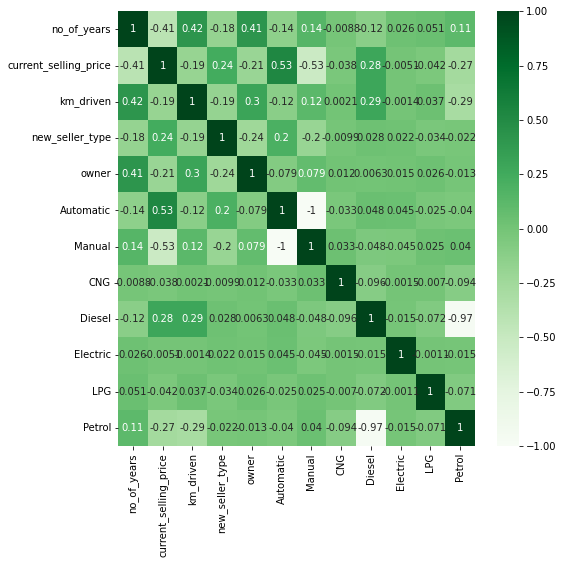

In [47]:
plt.figure(figsize=(8,8))
sns.heatmap(df.corr(),annot=True,cmap='Greens')

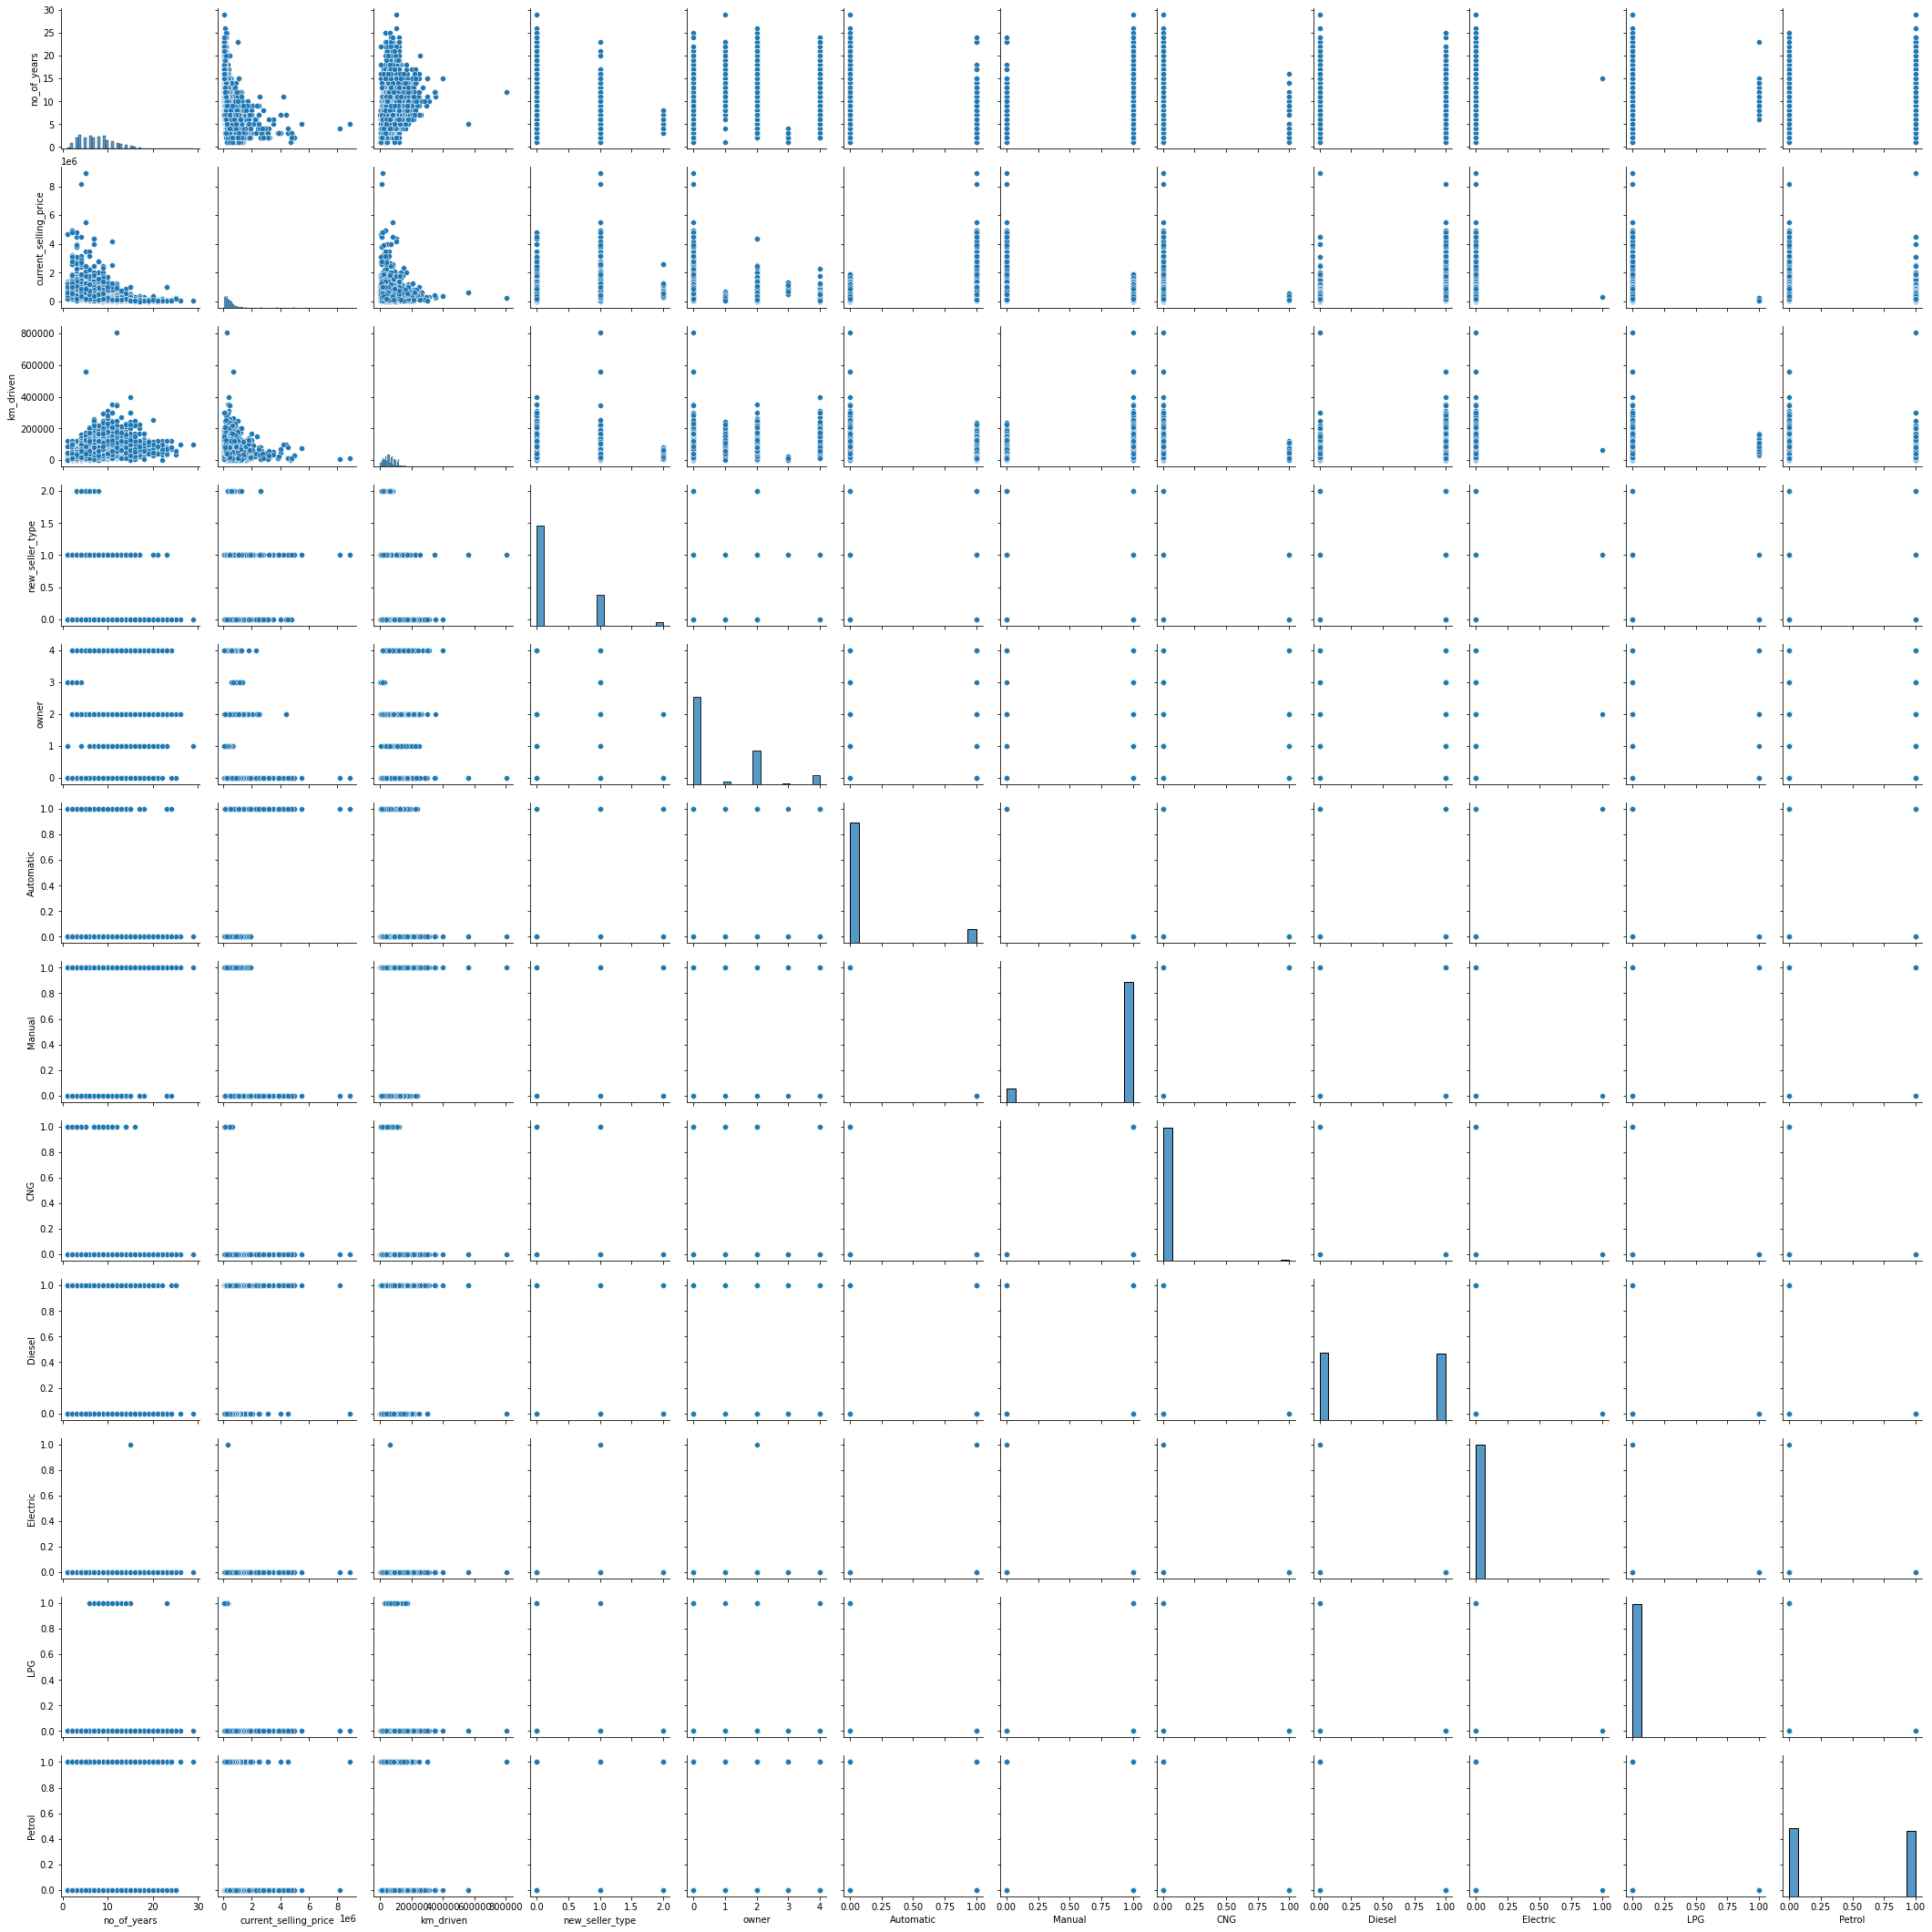

In [48]:
sns.pairplot(df)

{'whiskers': [<matplotlib.lines.Line2D at 0x20c99e984f0>,
 'caps': [<matplotlib.lines.Line2D at 0x20c99e98b20>,
 'boxes': [<matplotlib.lines.Line2D at 0x20c99e98310>,
 'medians': [<matplotlib.lines.Line2D at 0x20c99e99030>,
 'fliers': [<matplotlib.lines.Line2D at 0x20c99e992d0>,
 'means': []}

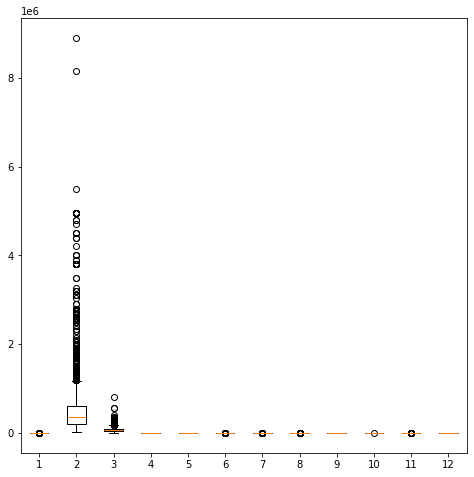

In [49]:
plt.figure(figsize=(8,8))
plt.boxplot(df)

### Machine Learning

In [50]:
X=np.array(df.drop('current_selling_price',axis=1))
Y=np.array(df.current_selling_price)

Splitting the data

In [51]:
X_train,X_test,Y_train,Y_test=train_test_split(X,Y,test_size=0.2,random_state=20,shuffle=True)

Choosing the model

In [52]:
model=DecisionTreeRegressor()

Training the model

In [53]:
model.fit(X_train,Y_train)

DecisionTreeRegressor()

In [54]:
Y_pred=model.predict(X_test)

Testing the model

In [55]:
Y_pred

array([ 345000.        ,  313333.33333333,  110000.        ,
        699000.        ,  200000.        ,  721111.        ,
        503999.8       ,   92800.        ,  415000.        ,
         70000.        ,  231666.33333333,  537000.        ,
        402000.        ,  362500.        ,  472999.8       ,
        125000.        ,  475000.        ,  315000.        ,
        315000.        ,  317142.85714286,  337500.        ,
        446833.16666667,  180000.        ,  928399.6       ,
        800000.        ,  160000.        ,  150000.        ,
        413333.33333333,  210000.        ,  185000.        ,
        800000.        ,  750000.        ,  790000.        ,
        225000.        ,  100000.        ,  650000.        ,
       3500000.        ,   70000.        ,  200000.        ,
        496428.57142857,  165000.        ,  557500.        ,
        590000.        ,  450000.        ,  385000.        ,
        360000.        ,  450000.        ,  900000.        ,
        611000.        ,

In [56]:
model.score(X_test,Y_test)

0.24317537308451043

In [57]:
r2_score(Y_test,Y_pred)

0.24317537308451043

Text(0.5, 1.0, 'Actual Values v/s Predicted Values')

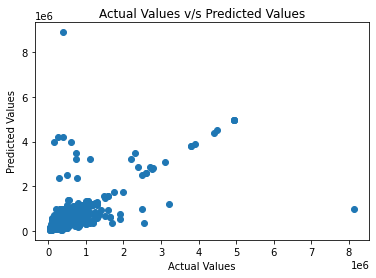

In [58]:
plt.scatter(Y_test,Y_pred)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual Values v/s Predicted Values')


In [59]:
mean_squared_error(Y_test,Y_pred)

307342208309.1624

In [60]:
mean_absolute_error(Y_test,Y_pred)

196559.34321064883

In [61]:
final_df=pd.DataFrame({'Actual Value':Y_test,'Predicted Value':Y_pred})

In [62]:
final_df.head()

,Actual Value,Predicted Value
0,500000,345000.000000
1,340000,313333.333333
2,110000,110000.000000
3,160000,699000.000000
4,114999,200000.000000


<Axes: >

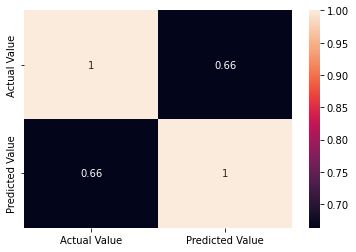

In [63]:
sns.heatmap(final_df.corr(),annot=True)